# Aprendizado de Máquina Aplicado a Requisitos de Teste (QA Gen)

**Disciplina:** Aprendizado de Máquina — Pós-Graduação em IA (INF/UFG)

Neste notebook exploramos a base `data/historico_requisitos.csv` e treinamos os três modelos utilizados no portal web:
1. **Regressão:** Previsão do esforço de teste em horas (`RandomForestRegressor`).
2. **Classificação:** Estimativa de risco de defeito em produção (`LogisticRegression`).
3. **Clusterização:** Agrupamento de requisitos por perfil (`KMeans`).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, silhouette_score
)

df = pd.read_csv('../data/historico_requisitos.csv')
print(f"Total de registros: {len(df)}")
df.head()

Total de registros: 300


,id,titulo,perfil,num_regras_negocio,num_casos_teste,num_integracoes,envolve_seguranca,esforco_teste_horas,gerou_bug_producao
0,1,Renegociação de contratos parcelados,Fluxo de Negócio,9,12,2,0,11.7,0
1,2,Anonimização de dados pessoais (LGPD),Crítico / Segurança,8,17,1,1,14.8,0
2,3,Webhook de notificações de pagamento,Integração Externa,4,6,4,0,9.6,1
3,4,Renegociação de contratos parcelados,Fluxo de Negócio,11,16,2,0,16.3,1
4,5,Exclusão lógica de fornecedores inativos,CRUD Simples,1,2,0,0,2.3,0


## 1. Análise Exploratória Básica

In [1]:
features = ['num_regras_negocio', 'num_casos_teste', 'num_integracoes', 'envolve_seguranca']
df[features + ['esforco_teste_horas', 'gerou_bug_producao']].describe().round(2)

,num_regras_negocio,num_casos_teste,num_integracoes,envolve_seguranca,esforco_teste_horas,gerou_bug_producao
count,300.00,300.00,300.00,300.00,300.00,300.00
mean,5.75,9.54,1.47,0.26,9.96,0.47
std,3.58,5.46,1.82,0.44,4.72,0.50
min,1.00,2.00,0.00,0.00,1.80,0.00
25%,3.00,5.00,0.00,0.00,4.90,0.00
50%,5.00,9.00,1.00,0.00,11.40,0.00
75%,8.00,14.00,2.00,1.00,13.90,1.00
max,14.00,21.00,7.00,1.00,18.10,1.00


## 2. Regressão — Previsão de Esforço (Horas)
Utilizamos o `RandomForestRegressor` para prever `esforco_teste_horas` a partir dos 4 indicadores do requisito.

R²:   0.95
MAE:  0.87 horas
RMSE: 1.05 horas


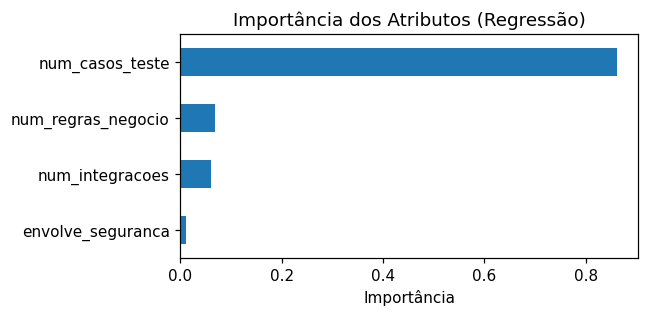

In [1]:
X = df[features].values
y_reg = df['esforco_teste_horas'].values

X_train, X_test, y_train, y_test = train_test_split(X, y_reg, test_size=0.2, random_state=42)

reg = RandomForestRegressor(n_estimators=100, random_state=42)
reg.fit(X_train, y_train)
y_pred_reg = reg.predict(X_test)

print(f"R²:   {r2_score(y_test, y_pred_reg):.2f}")
print(f"MAE:  {mean_absolute_error(y_test, y_pred_reg):.2f} horas")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_reg)):.2f} horas")

pd.Series(reg.feature_importances_, index=features).sort_values().plot(
    kind='barh', figsize=(6, 3), title='Importância dos Atributos (Regressão)'
)
plt.xlabel('Importância')
plt.tight_layout()
plt.show()

## 3. Classificação — Risco de Defeito em Produção
Treinamos uma `LogisticRegression` (com `StandardScaler`) para prever a ocorrência de problemas em produção (`gerou_bug_producao`).

In [1]:
y_clf = df['gerou_bug_producao'].values

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

clf = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(random_state=42))
])
clf.fit(X_train_c, y_train_c)
y_pred_c = clf.predict(X_test_c)

print(f"Acurácia: {accuracy_score(y_test_c, y_pred_c):.2%}")
print(f"Precisão: {precision_score(y_test_c, y_pred_c):.2%}")
print(f"Recall:   {recall_score(y_test_c, y_pred_c):.2%}")
print(f"F1-Score: {f1_score(y_test_c, y_pred_c):.2%}")
print("\nMatriz de Confusão:\n", confusion_matrix(y_test_c, y_pred_c))

Acurácia: 76.67%
Precisão: 71.88%
Recall:   82.14%
F1-Score: 76.67%

Matriz de Confusão:
 [[23  9]
 [ 5 23]]


## 4. Clusterização — Agrupamento de Requisitos (K-Means)
Aplicamos o `KMeans` com $k=4$ sobre os dados padronizados para agrupar os requisitos por similaridade.

In [1]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

print(f"Inércia:   {kmeans.inertia_:.1f}")
print(f"Silhueta:  {silhouette_score(X_scaled, clusters):.2f}")

centroides = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=features
).round(1).abs()
centroides.index = [f'Grupo {i}' for i in range(4)]
centroides

Inércia:   242.9
Silhueta:  0.59


,num_regras_negocio,num_casos_teste,num_integracoes,envolve_seguranca
Grupo 0,7.3,12.7,2.1,1.0
Grupo 1,2.5,3.9,0.1,0.0
Grupo 2,10.2,15.7,0.8,0.0
Grupo 3,5.0,9.7,4.7,0.1


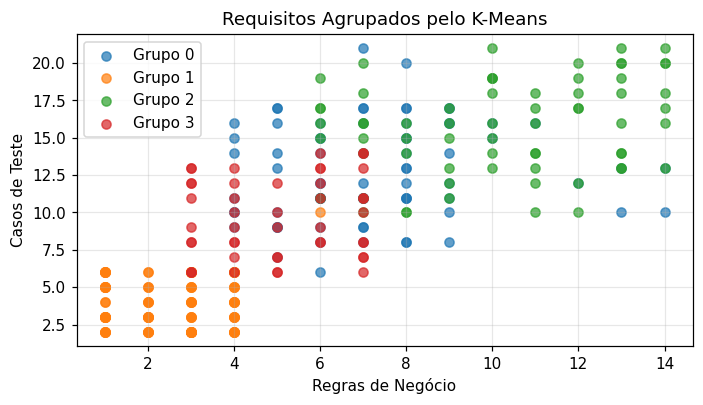

In [1]:
plt.figure(figsize=(6.5, 3.8))
for c in range(4):
    mask = clusters == c
    plt.scatter(X[mask, 0], X[mask, 1], label=f'Grupo {c}', alpha=0.7)

plt.xlabel('Regras de Negócio')
plt.ylabel('Casos de Teste')
plt.title('Requisitos Agrupados pelo K-Means')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()